In [4]:
import cv2 
import numpy as np 
import ipykernel 
print(f"OpenCV version: {cv2.__version__}") 
print(f"NumPy version: {np.__version__}") 
print(f"ipykernel version: {ipykernel.__version__}")

OpenCV version: 5.0.0
NumPy version: 2.5.4
ipykernel version: 7.4.0


# Test the Objects

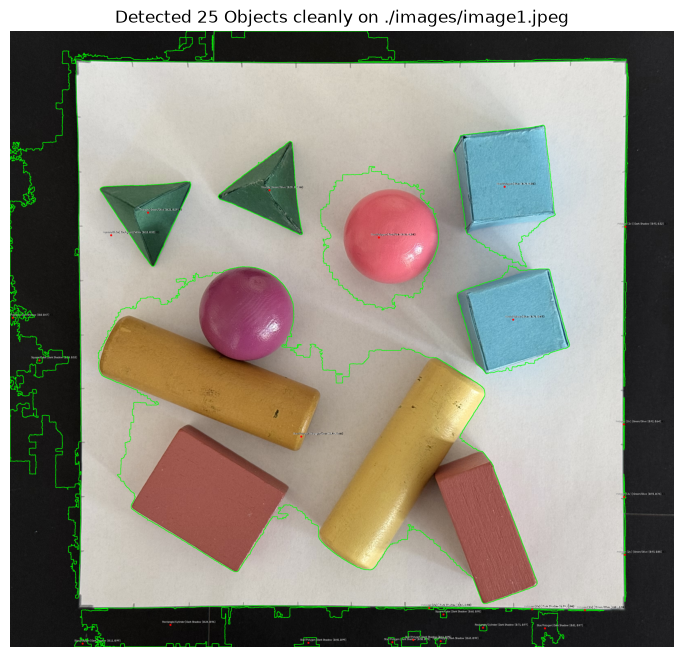

--- Object Detection Summary (25 Objects Found) ---
Object 28: Shape=Star/Polygon, Color=Dark Shadow, Position=(0.11, 0.99)
Object 30: Shape=Star/Polygon, Color=Dark Shadow, Position=(0.45, 0.99)
Object 31: Shape=Star/Polygon, Color=Dark Shadow, Position=(0.65, 0.99)
Object 32: Shape=Star/Polygon, Color=Dark Shadow, Position=(0.58, 0.99)
Object 43: Shape=Star/Polygon, Color=Dark Shadow, Position=(0.61, 0.99)
Object 48: Shape=Rectangle/Cylinder, Color=Dark Shadow, Position=(0.71, 0.97)
Object 64: Shape=Star/Polygon, Color=Dark Shadow, Position=(0.81, 0.97)
Object 66: Shape=Square/Cube, Color=Dark Shadow, Position=(0.65, 0.95)
Object 73: Shape=Polygon (2v), Color=Green/Olive, Position=(0.87, 0.94)
Object 78: Shape=Polygon (2v), Color=Dark Shadow, Position=(0.79, 0.94)
Object 79: Shape=Polygon (2v), Color=Dark Shadow, Position=(0.63, 0.94)
Object 80: Shape=Rectangle/Cylinder, Color=Dark Shadow, Position=(0.24, 0.96)
Object 122: Shape=Polygon (2v), Color=Green/Olive, Position=(0.93, 0.85)


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def classify_color_hsv(hsv_pixel):
    h, s, v = hsv_pixel
    if s < 30 and v > 150:
        return "Background/White"
    if v < 40:
        return "Dark Shadow"

    if (h >= 0 and h <= 10) or (h >= 170 and h <= 180):
        return "Red/Pink"
    elif 11 <= h <= 25:
        return "Orange/Coral"
    elif 26 <= h <= 35:
        return "Yellow/Beige"
    elif 36 <= h <= 85:
        return "Green/Olive"
    elif 86 <= h <= 125:
        return "Blue"
    elif 126 <= h <= 169:
        return "Purple/Magenta"
    else:
        return "Unknown"

def classify_shape(contour):
    perimeter = cv2.arcLength(contour, True)
    if perimeter == 0:
        return "Unknown"
    
    approx = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
    vertices = len(approx)
    area = cv2.contourArea(contour)
    circularity = 4 * np.pi * area / (perimeter * perimeter)
    
    if vertices == 3:
        return "Triangle"
    elif vertices == 4:
        x, y, w, h = cv2.boundingRect(approx)
        aspect_ratio = float(w) / h
        return "Square/Cube" if 0.88 <= aspect_ratio <= 1.12 else "Rectangle/Cylinder"
    elif vertices >= 5 and circularity < 0.65:
        return "Star/Polygon"
    elif circularity >= 0.65:
        return "Circle/Sphere"
    else:
        return f"Polygon ({vertices}v)"

# ---------------------------------------------------------
# 1. Load Image and Adaptive Binarization
# ---------------------------------------------------------
image_path = './images/image1.jpeg'  # Try 'objects2.jpeg' as well!
img_bgr = cv2.imread(image_path)

if img_bgr is None:
    raise FileNotFoundError(f"Could not load '{image_path}'.")

img_h, img_w, _ = img_bgr.shape
hsv_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# Extract Saturation channel (S) — objects are colorful, table is neutral
sat_channel = hsv_img[:, :, 1]
blurred_sat = cv2.GaussianBlur(sat_channel, (7, 7), 0)

# Saturation thresholding + Otsu fallback for clean background separation
_, binary_mask = cv2.threshold(blurred_sat, 30, 255, cv2.THRESH_BINARY)

# Morphological closing to fill minor gaps inside wooden figures
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
binary_cleaned = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

# ---------------------------------------------------------
# 2. Contour Extraction & Object Analysis
# ---------------------------------------------------------
contours, _ = cv2.findContours(binary_cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

annotated_img = img_bgr.copy()
detected_objects = []

for i, cnt in enumerate(contours):
    area = cv2.contourArea(cnt)
    
    # Filter out small noise artifacts
    if area < 600:
        continue

    # Centroid calculation
    M = cv2.moments(cnt)
    if M['m00'] != 0:
        cx = int(M['m10'] / M['m00'])
        cy = int(M['m01'] / M['m00'])
    else:
        continue

    norm_x = round(cx / img_w, 2)
    norm_y = round(cy / img_h, 2)

    # Sample color and classify shape
    sample_hsv = hsv_img[cy, cx]
    color_label = classify_color_hsv(sample_hsv)
    shape_label = classify_shape(cnt)

    detected_objects.append({
        'id': i + 1,
        'shape': shape_label,
        'color': color_label,
        'pos': (norm_x, norm_y)
    })

    # Draw bounding contours and centroids
    cv2.drawContours(annotated_img, [cnt], -1, (0, 255, 0), 2)
    cv2.circle(annotated_img, (cx, cy), 5, (0, 0, 255), -1)

    label_text = f"{shape_label} | {color_label} ({norm_x}, {norm_y})"
    cv2.putText(annotated_img, label_text, (cx - 40, cy - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 3)
    cv2.putText(annotated_img, label_text, (cx - 40, cy - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)

# ---------------------------------------------------------
# 3. Visualization
# ---------------------------------------------------------
annotated_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(annotated_rgb)
plt.title(f"Detected {len(detected_objects)} Objects cleanly on {image_path}")
plt.axis('off')
plt.show()

print(f"--- Object Detection Summary ({len(detected_objects)} Objects Found) ---")
for obj in detected_objects:
    print(f"Object {obj['id']}: Shape={obj['shape']}, Color={obj['color']}, Position={obj['pos']}")

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def classify_color_hsv(hsv_pixel):
    h, s, v = hsv_pixel
    if s < 30 and v > 150:
        return "Background/White"
    if v < 40:
        return "Dark Shadow"

    if (h >= 0 and h <= 10) or (h >= 170 and h <= 180):
        return "Red/Pink"
    elif 11 <= h <= 25:
        return "Orange/Coral"
    elif 26 <= h <= 35:
        return "Yellow/Beige"
    elif 36 <= h <= 85:
        return "Green/Olive"
    elif 86 <= h <= 125:
        return "Blue"
    elif 126 <= h <= 169:
        return "Purple/Magenta"
    else:
        return "Unknown"

def classify_shape(contour):
    perimeter = cv2.arcLength(contour, True)
    if perimeter == 0:
        return "Unknown"
    
    approx = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
    vertices = len(approx)
    area = cv2.contourArea(contour)
    circularity = 4 * np.pi * area / (perimeter * perimeter)
    
    if vertices == 3:
        return "Triangle"
    elif vertices == 4:
        x, y, w, h = cv2.boundingRect(approx)
        aspect_ratio = float(w) / h
        return "Square/Cube" if 0.88 <= aspect_ratio <= 1.12 else "Rectangle/Cylinder"
    elif vertices >= 5 and circularity < 0.65:
        return "Star/Polygon"
    elif circularity >= 0.65:
        return "Circle/Sphere"
    else:
        return f"Polygon ({vertices}v)"

# ---------------------------------------------------------
# 1. Load Image and Adaptive Binarization
# ---------------------------------------------------------
image_path = 'objects.jpeg'  # Try 'objects2.jpeg' as well!
img_bgr = cv2.imread(image_path)

if img_bgr is None:
    raise FileNotFoundError(f"Could not load '{image_path}'.")

img_h, img_w, _ = img_bgr.shape
hsv_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# Extract Saturation channel (S) — objects are colorful, table is neutral
sat_channel = hsv_img[:, :, 1]
blurred_sat = cv2.GaussianBlur(sat_channel, (7, 7), 0)

# Saturation thresholding + Otsu fallback for clean background separation
_, binary_mask = cv2.threshold(blurred_sat, 30, 255, cv2.THRESH_BINARY)

# Morphological closing to fill minor gaps inside wooden figures
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
binary_cleaned = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

# ---------------------------------------------------------
# 2. Contour Extraction & Object Analysis
# ---------------------------------------------------------
contours, _ = cv2.findContours(binary_cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

annotated_img = img_bgr.copy()
detected_objects = []

for i, cnt in enumerate(contours):
    area = cv2.contourArea(cnt)
    
    # Filter out small noise artifacts
    if area < 600:
        continue

    # Centroid calculation
    M = cv2.moments(cnt)
    if M['m00'] != 0:
        cx = int(M['m10'] / M['m00'])
        cy = int(M['m01'] / M['m00'])
    else:
        continue

    norm_x = round(cx / img_w, 2)
    norm_y = round(cy / img_h, 2)

    # Sample color and classify shape
    sample_hsv = hsv_img[cy, cx]
    color_label = classify_color_hsv(sample_hsv)
    shape_label = classify_shape(cnt)

    detected_objects.append({
        'id': i + 1,
        'shape': shape_label,
        'color': color_label,
        'pos': (norm_x, norm_y)
    })

    # Draw bounding contours and centroids
    cv2.drawContours(annotated_img, [cnt], -1, (0, 255, 0), 2)
    cv2.circle(annotated_img, (cx, cy), 5, (0, 0, 255), -1)

    label_text = f"{shape_label} | {color_label} ({norm_x}, {norm_y})"
    cv2.putText(annotated_img, label_text, (cx - 40, cy - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 3)
    cv2.putText(annotated_img, label_text, (cx - 40, cy - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)

# ---------------------------------------------------------
# 3. Visualization
# ---------------------------------------------------------
annotated_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(annotated_rgb)
plt.title(f"Detected {len(detected_objects)} Objects cleanly on {image_path}")
plt.axis('off')
plt.show()

print(f"--- Object Detection Summary ({len(detected_objects)} Objects Found) ---")
for obj in detected_objects:
    print(f"Object {obj['id']}: Shape={obj['shape']}, Color={obj['color']}, Position={obj['pos']}")

[ WARN:0@2.521] global loadsave.cpp:278 findDecoder imread_('objects.jpeg'): can't open/read file: check file path/integrity


FileNotFoundError: Could not load 'objects.jpeg'.

# Step 1: Calibration Validation

Detect the black sheet frame, warp it to a top-down square, and verify the
normalized coordinate mapping (top-left origin, per the project specification).

In [ ]:
import os
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Make the local "src" package importable from the notebook.
sys.path.insert(0, os.path.abspath("."))

from src.calibration import (
    find_sheet_corners,
    order_corners,
    warp_sheet,
    pixel_to_normalized,
)

# Images that use the current setup (black border + corner squares).
test_images = ["image10", "image11", "image12", "image13"]
warp_size = 800

fig, axes = plt.subplots(len(test_images), 2, figsize=(10, 5 * len(test_images)))

for row, name in enumerate(test_images):
    img_bgr = cv2.imread(f"images/{name}.jpeg")
    if img_bgr is None:
        raise FileNotFoundError(f"Could not load images/{name}.jpeg")

    corners = find_sheet_corners(img_bgr)

    # Left column: original image with detected corners drawn on top.
    overlay = img_bgr.copy()
    if corners is not None:
        ordered = order_corners(corners)
        cv2.polylines(
            overlay, [ordered.astype(np.int32)], True, (0, 255, 0), 8
        )
        # Label the four corners in their canonical order.
        for label, point in zip(["TL", "TR", "BR", "BL"], ordered):
            px, py = int(point[0]), int(point[1])
            cv2.circle(overlay, (px, py), 20, (0, 0, 255), -1)
            cv2.putText(
                overlay, label, (px + 25, py),
                cv2.FONT_HERSHEY_SIMPLEX, 2.0, (0, 0, 255), 5,
            )
        status = "frame detected"
    else:
        status = "NO FRAME FOUND"

    axes[row, 0].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f"{name}: {status}")
    axes[row, 0].axis("off")

    # Right column: the perspective-corrected (warped) sheet.
    if corners is not None:
        warped, _ = warp_sheet(img_bgr, corners, size=warp_size)
        axes[row, 1].imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
        axes[row, 1].set_title(f"{name}: warped {warp_size}x{warp_size}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

# Sanity check: verify the normalized coordinate convention (top-left origin).
print("Normalized coordinate checks (top-left origin, per specification):")
print("  warped (0, 0)            ->", pixel_to_normalized(0, 0, warp_size))
print("  warped center            ->",
      pixel_to_normalized(warp_size // 2, warp_size // 2, warp_size))
print("  warped (size, size) BR   ->",
      pixel_to_normalized(warp_size, warp_size, warp_size))